In [1]:
import shap
import torch
import transformers
from datasets import load_dataset
import numpy as np

# Upewniamy się, czy CUDA w ogóle jest dostępna w PyTorchu
if not torch.cuda.is_available():
    print("UWAGA: PyTorch nie widzi karty graficznej")
else:
    print(f"Sukces: Wykryto kartę: {torch.cuda.get_device_name(0)}")

# 1. Konfiguracja sprzętowa i ładowanie modelu bezpośrednio na GPU
model_name = "microsoft/phi-2"

print(f"Ładowanie modelu {model_name}...")
tokenizer = transformers.AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)

# Ładujemy model od razu na pierwszą kartę CUDA w precyzji bfloat16
model = transformers.AutoModelForCausalLM.from_pretrained(
    model_name, 
    torch_dtype=torch.bfloat16,
    trust_remote_code=True
).cuda()  # <--- Jawne wymuszenie GPU zamiast device_map="auto"

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.pad_token_id


# 2. Pobranie danych i przygotowanie promptu
print("Pobieranie zbioru danych SST-2...")
raw_dataset = load_dataset("sst2", split="validation[:1]")
test_prompt = f"Review: {raw_dataset['sentence'][0]}\nSentiment:"

input_ids = tokenizer.encode(test_prompt, return_tensors="np")
input_ids_flat = input_ids[0]


# 3. Poprawiona funkcja przewidująca w 100% działająca na GPU
def predict_tokens(token_ids_batch):
    # SHAP potrafi przekazać tablicę 1D lub 2D w zależności od etapu permutowania.
    # Wymuszamy kształt (batch_size, sequence_length)
    if len(token_ids_batch.shape) == 1:
        token_ids_batch = np.expand_dims(token_ids_batch, axis=0)
        
    # Zamieniamy na tensor i wysyłamy na GPU (.cuda())
    token_ids_tensor = torch.tensor(token_ids_batch, dtype=torch.long).cuda()
    
    with torch.no_grad():
        outputs = model(input_ids=token_ids_tensor)
        # Pobieramy logity dla ostatniego tokenu
        next_token_logits = outputs.logits[:, -1, :]
        probs = torch.softmax(next_token_logits, dim=-1).float().cpu().numpy()
    return probs


# 4. Inicjalizacja SHAP
print("Inicjalizacja SHAP Explainer (Tabular Mode)...")
background = np.zeros(input_ids.shape)
explainer = shap.Explainer(predict_tokens, background)


# 5. Obliczenia na GPU
print("Obliczanie wartości SHAP dla tokenów na karcie graficznej...")
# max_evals=100 na RTX 4060 powinno przelecieć błyskawicznie
shap_values = explainer(input_ids, max_evals=100)

# Mapujemy tokeny z powrotem na tekst
feature_names = [tokenizer.decode([tid]) for tid in input_ids_flat]
shap_values.feature_names = feature_names

print("Gotowe! Obliczenia zakończone sukcesem na GPU.")

Sukces: Wykryto kartę: NVIDIA GeForce RTX 4060 Laptop GPU
Ładowanie modelu microsoft/phi-2...


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Pobieranie zbioru danych SST-2...
Inicjalizacja SHAP Explainer (Tabular Mode)...
Obliczanie wartości SHAP dla tokenów na karcie graficznej...


PermutationExplainer explainer: 2it [00:12, 12.47s/it]               

Gotowe! Obliczenia zakończone sukcesem na GPU.


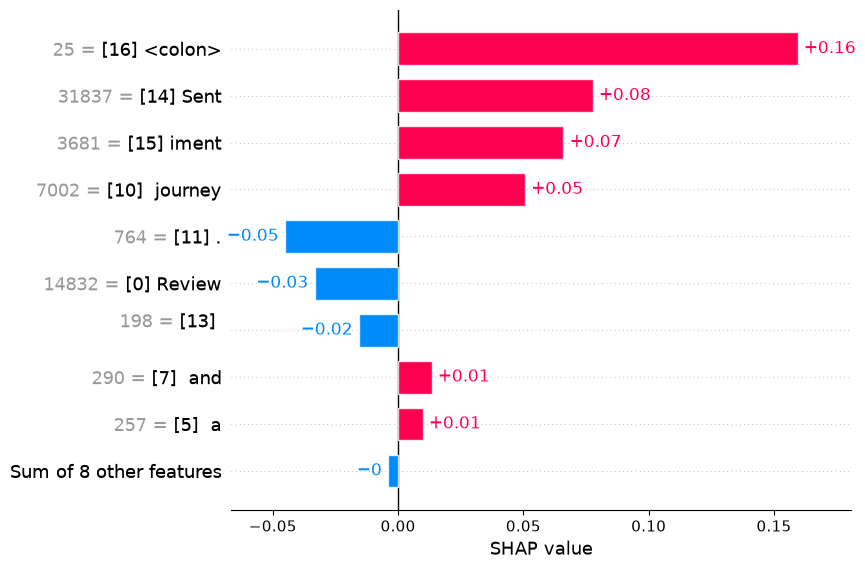

In [8]:
import shap

# 1. Sprawdzamy przewidziany token
predicted_token_id = np.argmax(predict_tokens(input_ids))

# 2. Wyciągamy czyste tablice liczbowe z SHAP (bez atrybutów tekstowych)
raw_values = shap_values[0, :, predicted_token_id].values
raw_base_values = shap_values[0, :, predicted_token_id].base_values
raw_data = shap_values[0, :, predicted_token_id].data

# 3. Przygotowujemy bezpieczne nazwy (tak jak poprzednio)
safe_feature_names = []
for i, name in enumerate(feature_names):
    safe_name = name.replace(":", "<colon>") 
    safe_feature_names.append(f"[{i}] {safe_name}")

# 4. Tworzymy nowy, całkowicie czysty obiekt Explanation od zera
clean_shap_obj = shap.Explanation(
    values=raw_values,
    base_values=raw_base_values,
    data=raw_data,
    feature_names=safe_feature_names
)

# 5. Generujemy poprawny wykres słupkowy
shap.plots.bar(clean_shap_obj)